=== Dataset Overview ===
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Shape: (150, 5)

Class Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


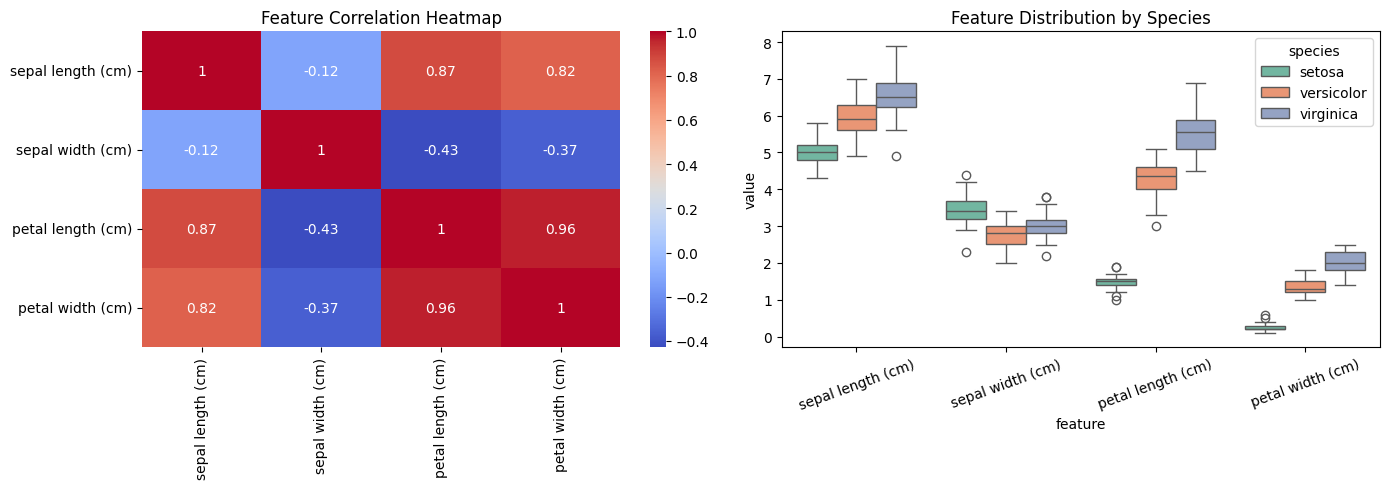


[Saved] iris_eda.png & iris_pairplot.png

=== Model Evaluation ===
Accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



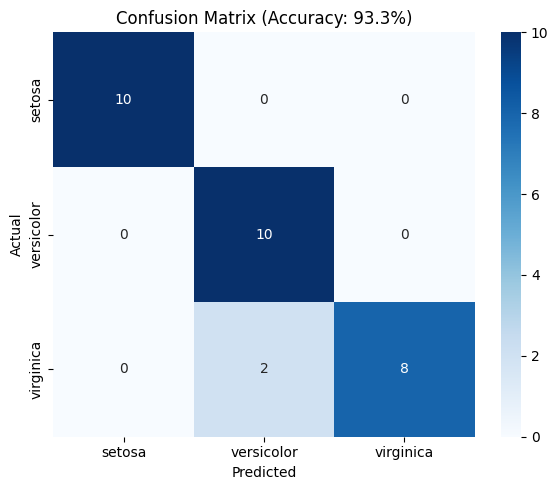

[Saved] iris_confusion_matrix.png

       🌸 IRIS FLOWER PREDICTOR 🌸
Enter the measurements of your flower.
The model will predict its species!

Enter the following measurements (in cm):
  Sepal Length (e.g. 5.1): 5.1
  Sepal Width  (e.g. 3.5): 3.5
  Petal Length (e.g. 1.4): 1.4
  Petal Width  (e.g. 0.2): 0.2

──────────────────────────────
  Predicted Species : SETOSA
  Confidence Scores :
    setosa       100.0%  ████████████████████
    versicolor     0.0%  
    virginica      0.0%  
──────────────────────────────

Predict another flower? (yes/no): yes

Enter the following measurements (in cm):
  Sepal Length (e.g. 5.1): 5.1
  Sepal Width  (e.g. 3.5): 3.5
  Petal Length (e.g. 1.4): 1.4
  Petal Width  (e.g. 0.2): 0.2

──────────────────────────────
  Predicted Species : SETOSA
  Confidence Scores :
    setosa       100.0%  ████████████████████
    versicolor     0.0%  
    virginica      0.0%  
──────────────────────────────


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)


iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("=== Dataset Overview ===")
print(df.head())
print(f"\nShape: {df.shape}")
print("\nClass Distribution:")
print(df['species'].value_counts())


fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.pairplot(df, hue='species', palette='Set2')
plt.suptitle('Iris Pairplot', y=1.02)
plt.savefig('iris_pairplot.png', bbox_inches='tight')
plt.close()


ax = axes[0]
corr = df.drop('species', axis=1).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', ax=ax)
ax.set_title('Feature Correlation Heatmap')


df_melt = df.melt(id_vars='species', var_name='feature', value_name='value')
sns.boxplot(data=df_melt, x='feature', y='value', hue='species',
            palette='Set2', ax=axes[1])
axes[1].set_title('Feature Distribution by Species')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('iris_eda.png', bbox_inches='tight', dpi=150)
plt.show()
print("\n[Saved] iris_eda.png & iris_pairplot.png")


X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)


model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("\n=== Model Evaluation ===")
print(f"Accuracy: {acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))


cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.title(f'Confusion Matrix (Accuracy: {acc*100:.1f}%)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('iris_confusion_matrix.png', dpi=150)
plt.show()
print("[Saved] iris_confusion_matrix.png")


print("\n" + "="*50)
print("       🌸 IRIS FLOWER PREDICTOR 🌸")
print("="*50)
print("Enter the measurements of your flower.")
print("The model will predict its species!\n")

while True:
    try:
        print("Enter the following measurements (in cm):")
        sepal_length = float(input("  Sepal Length (e.g. 5.1): "))
        sepal_width  = float(input("  Sepal Width  (e.g. 3.5): "))
        petal_length = float(input("  Petal Length (e.g. 1.4): "))
        petal_width  = float(input("  Petal Width  (e.g. 0.2): "))

        sample = np.array([[sepal_length, sepal_width, petal_length, petal_width]])
        sample_scaled = scaler.transform(sample)

        prediction    = model.predict(sample_scaled)
        species       = iris.target_names[prediction[0]]
        proba         = model.predict_proba(sample_scaled)[0]

        print("\n──────────────────────────────")
        print(f"  Predicted Species : {species.upper()}")
        print("  Confidence Scores :")
        for name, prob in zip(iris.target_names, proba):
            bar = "█" * int(prob * 20)
            print(f"    {name:<12} {prob*100:5.1f}%  {bar}")
        print("──────────────────────────────")

    except ValueError:
        print("⚠️  Invalid input! Please enter numeric values only.\n")

    again = input("\nPredict another flower? (yes/no): ").strip().lower()
    if again not in ('yes', 'y'):
        print("\nThank you for using the Iris Predictor! 🌸")
        break
    print()
